# Seeing the stock network

Each dot keeps a fixed anchor. The stronger a stock moves with its peers, the further inward its dot travels. A spanning tree keeps just enough links to connect all the dots.

This is a seeded teaching example. Dates are illustrative.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from panic_detector.features.returns import daily_log_returns

rng = np.random.default_rng(2020)
dates = pd.bdate_range("2019-01-02", periods=320)
common = rng.normal(size=(320, 1))
strength = np.where(np.arange(320)[:, None] < 200, 0.18, 1.6)
moves = 0.009 * (rng.normal(size=(320, 8)) + strength * common)
prices = pd.DataFrame(100 * np.exp(moves.cumsum(axis=0)), index=dates, columns=list("ABCDEFGH"))
returns = daily_log_returns(prices)

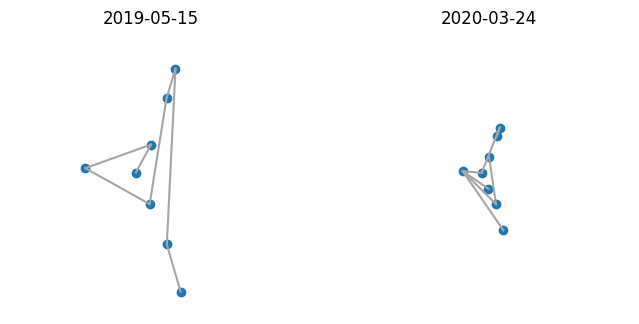

In [2]:
from panic_detector.analysis import analyze
from panic_detector.viz.plots import scene
history = scene(analyze(prices, 60), mode=1, cutoff=0.5)
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, i in zip(axes, (35, -1)):
    for endpoints in history.lines[i]:
        for pair in endpoints.T.reshape(-1, 2, 2):
            ax.plot(*pair.T, color="0.65")
    ax.scatter(*history.positions[i].T)
    ax.set(xlim=(-1.1, 1.1), ylim=(-1.1, 1.1), aspect="equal", title=history.rows[i]["date"])
    ax.axis("off")
display(fig); plt.close(fig)